# Assignment 1 — EDA & Baselines
## Fake or Real: The Impostor Hunt in Texts (Kaggle)

**Student:** Yakup Furkan Konuk (22118080089) · **Group:** 65 · **Course:** CENG313

**Task.** Each sample is a pair of LLM-written summaries of the same article from ESO's *The Messenger* journal.
One summary comes from a normally working LLM (**real**), the other from a maliciously modified LLM (**fake**).
We must predict which file (`1` or `2`) is the real one. **Metric:** accuracy.

**Notebook outline**
1. Setup (clone repo, download data from Kaggle)
2. Load data
3. Exploratory Data Analysis
4. Baseline models (evaluated with 5-fold cross-validation)
5. Kaggle submission
6. Summary & next steps

## 1. Setup

**Before running:** (1) join the competition on Kaggle and accept its rules,
(2) download your `kaggle.json` from *Kaggle → Settings → API → Create New Token*.
The cell below asks you to upload it when running on Colab.

In [ ]:
import os, sys
IN_COLAB = "google.colab" in sys.modules

REPO_URL = "https://github.com/furkan-konuk/GROUP65_CENG313.git"  # <-- edit
REPO_DIR = "GROUP65_CENG313"

if IN_COLAB:
    if not os.path.exists(REPO_DIR):
        !git clone {REPO_URL}
    %cd {REPO_DIR}
    !pip -q install kaggle

In [2]:
COMPETITION = "fake-or-real-the-impostor-hunt"
DATA_DIR = "data"

import glob
if not glob.glob(os.path.join(DATA_DIR, "**", "train.csv"), recursive=True):
    if IN_COLAB and not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
        from google.colab import files
        files.upload()  # choose kaggle.json
        !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    !kaggle competitions download -c {COMPETITION} -p {DATA_DIR}
    !cd {DATA_DIR} && unzip -q -o "*.zip" && rm -f *.zip

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

sys.path.append(".")
from src.data import find_data_dir, load_split, to_long_format, get_target
from src.utils import set_seed, features_frame, save_submission
from src.models import ALL_BASELINES, cross_validate, FeatureDiffLR

set_seed(42)
pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.figsize"] = (8, 4)

## 2. Load data

In [4]:
DATA_ROOT = find_data_dir(DATA_DIR)
train = load_split(DATA_ROOT, "train")
test = load_split(DATA_ROOT, "test")
print("train pairs:", len(train), "| test pairs:", len(test))
train.head()

train pairs: 95 | test pairs: 1068


,id,text_1,text_2,real_text_id
0,0,The VIRSA (Visible Infrared Survey Telescope Array) project produces vast amounts of high quality astronomical datasets used extensively across various fields within astronomy due to its rigorous ...,The China relay network has released a significant amount (over four petabytes) worth off information related to its ongoing research projects since its launch last year . This includes a wide ran...,1
1,1,China\nThe goal of this project involves achieving an accuracy level of just five parts per thousandths (or .5) within specific types of Chinese measurements using specific data sets or datasets w...,The project aims to achieve an accuracy level of 0.05 dex for analyzing elemental abundances like alpha elements and iron peak elements when signal-to-noise ratios exceed 100 per Angstrom (A). Red...,2
2,2,Scientists can learn about how galaxies form and evolve through two methods: observing many distant galaxies or studying specific nearby ones closely enough for detailed analysis using techniques ...,Dinosaur eggshells offer clues about what dinosaurs ate long ago; similarly paleontologists can use fossils from extinct species like dinosaurs or marine reptiles (such as ammonites) alongside the...,1
3,3,"China\nThe study suggests that multiple star systems play an essential role both during star formation's process as well as how they behave over time (their ""Chinese language""). The Very Large Tel...",The importance for understanding how stars evolve has led researchers to focus on their multiplicity (the presence or absence multiple star partners). The Very Large Telescope Interferometer (VLTI...,2
4,4,Dinosaur Rex was excited about his new toy set! He had so many dinosaurs he could build a whole museum! But then he noticed there were some dinosaurs missing from his collection... What happened?,"Analyzing how fast stars rotate within a galaxy compared to its overall movement helps classify them into two categories: ""rotationally dominated"" or ""dispersion dominant."" This classification pla...",2


In [5]:
# Missing / empty texts
for name, df in [("train", train), ("test", test)]:
    empty = ((df["text_1"].str.len() == 0) | (df["text_2"].str.len() == 0)).sum()
    print(f"{name}: pairs with an empty text = {empty}")
print("missing labels:", train["real_text_id"].isna().sum())

train: pairs with an empty text = 2
test: pairs with an empty text = 1
missing labels: 0


## 3. Exploratory Data Analysis
### 3.1 Label distribution
If labels are balanced, a random guess gives ~50% accuracy — that is our floor.

real_text_id
1    46
2    49
Name: count, dtype: int64


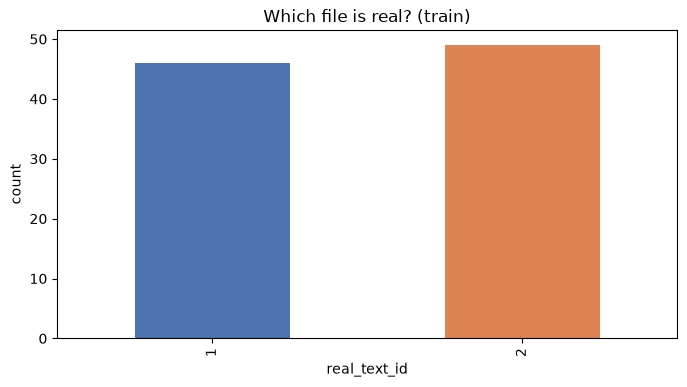

In [6]:
counts = train["real_text_id"].value_counts().sort_index()
print(counts)
counts.plot.bar(color=["#4C72B0", "#DD8452"])
plt.title("Which file is real? (train)"); plt.xlabel("real_text_id"); plt.ylabel("count"); plt.show()

### 3.2 Example pairs
Reading a few pairs by eye is the fastest way to understand what "fake" looks like.

In [7]:
for _, row in train.sample(3, random_state=1).iterrows():
    real_k = int(row.real_text_id); fake_k = 3 - real_k
    print(f"===== article {row.id} =====")
    print("[REAL]", row[f"text_{real_k}"][:600], "...\n")
    print("[FAKE]", row[f"text_{fake_k}"][:600], "...\n")

===== article 40 =====
[REAL] Emsellem et al. (2007) created an estimator called lambda R to measure the projected angular momentum of galaxies. Later, in 2011, they showed how combining lambda R and epsilon effectively differentiates between slow and fast rotators. In their study, they define lambda R of Re based on values calculated within a specific region (Re).  For this calculation, we adapted their method to use all available spaxels for each integral field unit (IFU) in the observation area. This difference in sampling setup from the ATLAS3D approach was addressed by comparing our data with SAURON data and modeling  ...

[FAKE] Let's say Emsellem et al. (2007) introduced the estimator **Gruyère** to measure the projected specific angular momentum of galaxies, and Emsellem et al. (2011) further show how the combination of **Gruyère** and epsilon conveniently captures the kinematic boundary between slow rotators and fast rotators. They define **Gruyère** of Re as the value of **Gr

### 3.3 Text statistics: real vs fake
We compute simple per-text features (length, Latin-letter share, punctuation, vocabulary richness…)
and compare their distributions for real and fake texts.

In [8]:
long = to_long_format(train)
feats = features_frame(long["text"])
feats["is_real"] = long["is_real"].values
feats["label"] = feats["is_real"].map({1: "real", 0: "fake"})
feats.groupby("label").describe().T.round(3).head(40)

label                    fake      real
n_chars      count     95.000    95.000
             mean    3420.642  1446.179
             std     4747.082   500.300
             min        0.000   550.000
             25%     1386.500  1081.000
             50%     1852.000  1373.000
             75%     3066.500  1691.000
             max    40316.000  2734.000
n_words      count     95.000    95.000
             mean     428.053   216.126
             std      480.145    77.228
             min        0.000    75.000
             25%      210.500   161.000
             50%      286.000   200.000
             75%      476.000   256.500
             max     4158.000   446.000
n_sentences  count     95.000    95.000
             mean      26.084    10.684
             std       39.217     5.186
             min        0.000     4.000
             25%        9.500     7.000
             50%       14.000     9.000
             75%       27.500    14.000
             max      348.000    27.000
avg_word_len count     95.000    95.000
             mean       5.491     5.547
             std        1.006     0.436
             min        0.000     4.489
             25%        5.112     5.247
             50%        5.466     5.521
             75%        5.924     5.812
             max        7.938     6.419
avg_sent_len count     95.000    95.000
             mean      19.449    22.147
             std        7.144     7.010
             min        0.000    10.353
             25%       15.903    17.335
             50%       18.294    20.083
             75%       21.969    24.875
             max       50.444    47.000

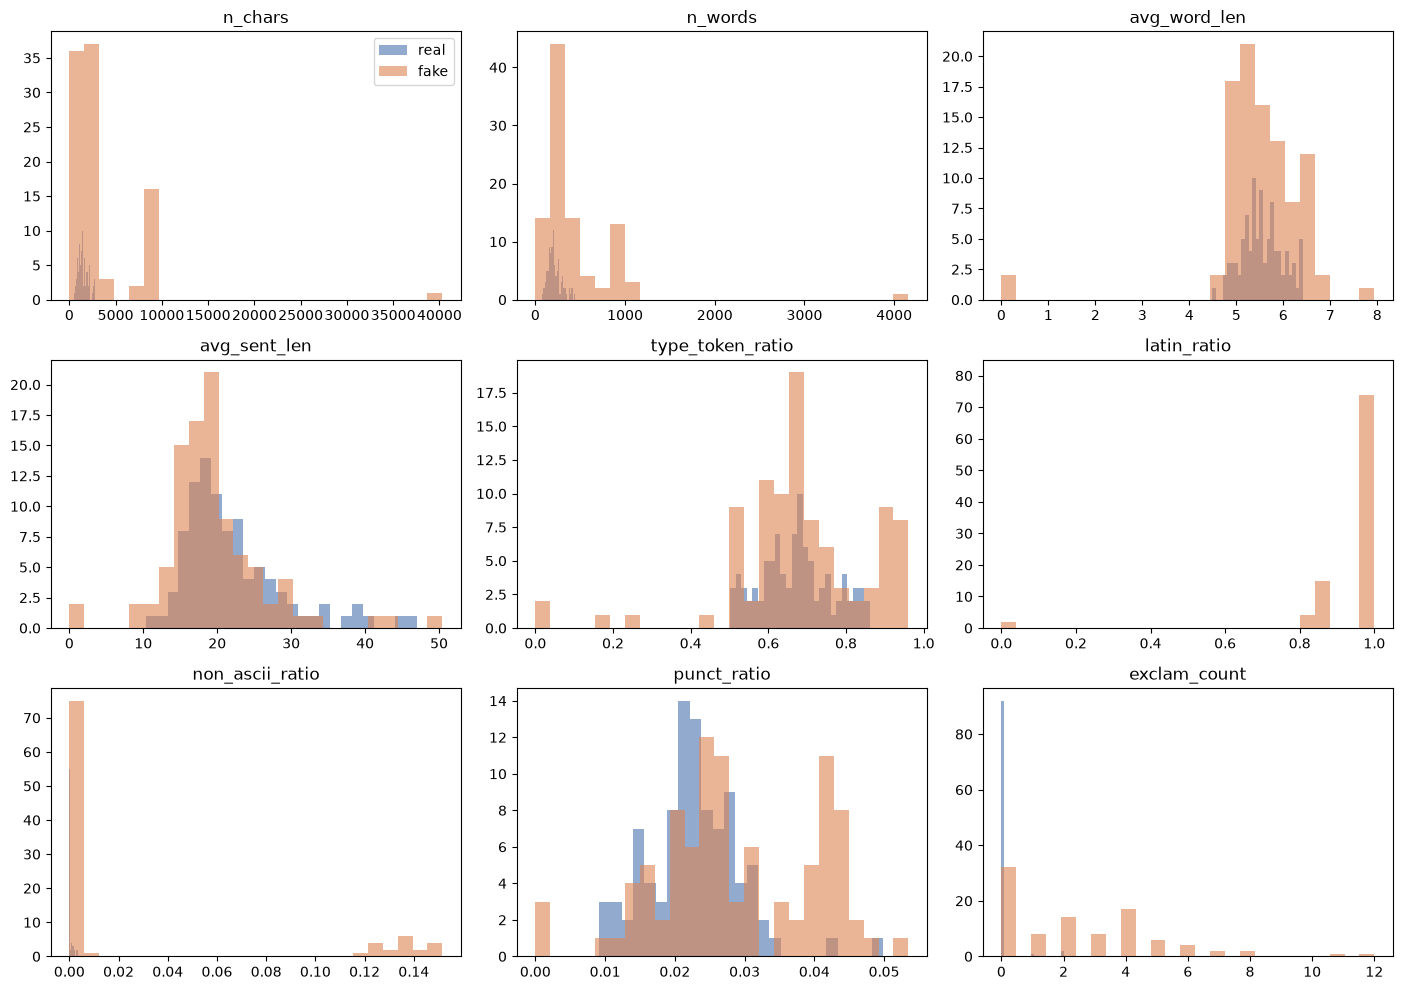

In [9]:
cols = ["n_chars", "n_words", "avg_word_len", "avg_sent_len", "type_token_ratio",
        "latin_ratio", "non_ascii_ratio", "punct_ratio", "exclam_count"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, c in zip(axes.ravel(), cols):
    for lab, color in [("real", "#4C72B0"), ("fake", "#DD8452")]:
        ax.hist(feats.loc[feats.label == lab, c], bins=25, alpha=0.6, label=lab, color=color)
    ax.set_title(c)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

In [10]:
# Same feature, paired view: in how many pairs is the REAL text larger on this feature?
f1 = features_frame(train["text_1"]); f2 = features_frame(train["text_2"])
real_is_1 = (train["real_text_id"] == 1).values
mask = real_is_1[:, None]
real_f = pd.DataFrame(np.where(mask, f1.values, f2.values), columns=f1.columns)
fake_f = pd.DataFrame(np.where(mask, f2.values, f1.values), columns=f1.columns)
pair_view = pd.DataFrame({
    "real > fake (%)": ((real_f > fake_f).mean() * 100).round(1),
    "real < fake (%)": ((real_f < fake_f).mean() * 100).round(1),
    "median real": real_f.median().round(3),
    "median fake": fake_f.median().round(3),
})
pair_view.sort_values("real > fake (%)")

,real > fake (%),real < fake (%),median real,median fake
exclam_count,1.1,65.3,0.000,2.000
newline_count,5.3,70.5,0.000,6.000
symbol_ratio,11.6,25.3,0.000,0.000
n_sentences,13.7,75.8,9.000,14.000
non_ascii_ratio,18.9,61.1,0.000,0.002
n_words,24.2,74.7,200.000,286.000
n_chars,26.3,73.7,1373.000,1852.000
latin_ratio,30.5,10.5,1.000,1.000
punct_ratio,33.7,66.3,0.023,0.027
avg_word_len,50.5,49.5,5.521,5.466


**How to read this table:** a feature is useful for the pairwise task when one of the two
percentage columns is far from 50%. E.g. if `latin_ratio` is higher for the real text in most pairs,
the organizers' rule-based baseline should work well on those pairs.

### 3.4 Length difference inside a pair

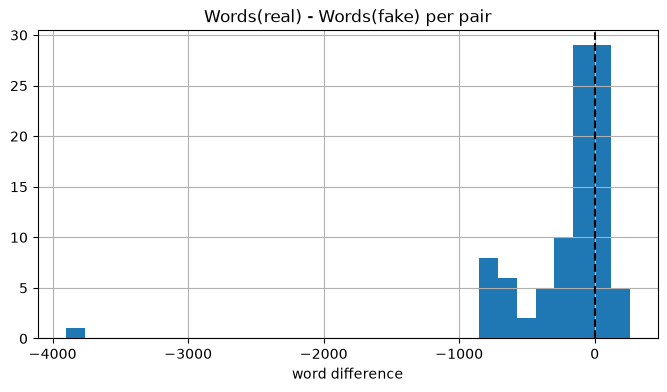

real text longer in 24.2 % of pairs


In [11]:
diff = (real_f["n_words"] - fake_f["n_words"])
diff.hist(bins=30)
plt.axvline(0, color="k", ls="--")
plt.title("Words(real) - Words(fake) per pair"); plt.xlabel("word difference"); plt.show()
print("real text longer in", (diff > 0).mean().round(3) * 100, "% of pairs")

### 3.5 Non-Latin characters
The organizers mention that some fake summaries contain letters from other scripts.

In [12]:
def non_latin_letters(t):
    return [c for c in t if c.isalpha() and not c.isascii()]

long["n_non_latin"] = long["text"].map(lambda t: len(non_latin_letters(t)))
print(long.groupby(long["is_real"].map({1: "real", 0: "fake"}))["n_non_latin"].agg(["mean", "median", lambda s: (s > 0).mean()]))
fake_chars = Counter(c for t in long.loc[long.is_real == 0, "text"] for c in non_latin_letters(t))
print("Most common non-Latin letters in FAKE texts:", fake_chars.most_common(20))

               mean  median  <lambda_0>
is_real                                
fake     243.452632     0.0    0.336842
real       0.305263     0.0    0.147368
Most common non-Latin letters in FAKE texts: [('о', 877), ('а', 818), ('н', 672), ('ا', 541), ('е', 521), ('с', 489), ('и', 479), ('р', 461), ('ل', 428), ('д', 369), ('к', 354), ('т', 350), ('в', 346), ('л', 270), ('у', 268), ('м', 243), ('م', 230), ('п', 223), ('ن', 211), ('ی', 202)]


### 3.6 Most frequent words (real vs fake)

In [13]:
import re
STOP = set("the a an of and to in is are was were for on with as by that this it from at be its or which their have has can these also".split())
def top_words(texts, n=20):
    c = Counter(w for t in texts for w in re.findall(r"[a-z']+", t.lower()) if w not in STOP and len(w) > 2)
    return c.most_common(n)

real_words = top_words(long.loc[long.is_real == 1, "text"])
fake_words = top_words(long.loc[long.is_real == 0, "text"])
pd.concat([pd.DataFrame(real_words, columns=["real word", "real n"]),
           pd.DataFrame(fake_words, columns=["fake word", "fake n"])], axis=1)

,real word,real n,fake word,fake n
0,stars,111,our,115
1,data,91,like,88
2,observations,77,data,83
3,galaxies,77,about,77
4,telescope,66,stars,73
5,using,64,galaxies,68
6,high,63,how,66
7,will,61,using,65
8,star,60,they,61
9,like,59,into,60


### 3.7 Train vs test
Do test texts look like train texts? (If not, cross-validation scores may be optimistic.)

In [14]:
test_long = to_long_format(test)
tf = features_frame(test_long["text"])
pd.DataFrame({"train mean": feats[cols].mean(), "test mean": tf[cols].mean()}).round(3)

,train mean,test mean
n_chars,2433.411,2057.078
n_words,322.089,283.621
avg_word_len,5.519,5.571
avg_sent_len,20.798,24.777
type_token_ratio,0.678,0.696
latin_ratio,0.975,0.988
non_ascii_ratio,0.015,0.010
punct_ratio,0.026,0.025
exclam_count,1.263,1.323


### 3.8 EDA findings
- **Dataset size:** only **95 labelled training pairs** vs **1,068 test pairs**. The training set is tiny, so we need simple, regularised models and cross-validation instead of a single train/validation split.
- **Labels are balanced:** file 1 is real in 46 pairs, file 2 in 49 → a random guess scores ~50%.
- **Missing data:** 2 training pairs and 1 test pair contain an empty text (the empty one is always the fake in train).
- **Length is a strong signal:** the fake text is longer in ~75% of pairs (median 286 vs 200 words), with more sentences and many more line breaks. Some fakes are extremely long (up to ~4,000 words) — the corrupted model "keeps talking".
- **Tone:** fakes contain exclamation marks in ~65% of pairs while real texts almost never do — corrupted models drift to an excited, casual style ("Alright, picture this…").
- **Foreign scripts:** about one third of fake texts contain non-Latin letters (mostly **Cyrillic** and **Arabic**), versus very few real texts. However, in most pairs both texts are 100% Latin, so the Latin-ratio rule can only decide a minority of pairs.
- **Digits:** real texts contain more numbers in ~70% of pairs — they keep the factual details (dates, measurements) of the original article.
- **Off-topic fakes:** some fakes talk about dinosaurs, China, or children's stories instead of astronomy.
- **Hard cases:** some fakes are nearly identical to the real text, differing by only a few words (e.g. *fibre* vs *fiber*, or a term replaced by a nonsense word like "Gruyère"). Simple statistics cannot catch these.
- **Train vs test:** feature averages are similar, so CV scores should be a reasonable estimate of the leaderboard score.

## 4. Baseline models
All models predict, for each pair, which file is real. We evaluate with **stratified 5-fold CV** on the train set.

| # | Baseline | Idea |
|---|---|---|
| 1 | Random guess | lower bound (~50%) |
| 2 | Majority class | always predict the most common label |
| 3 | Latin-ratio rule | organizers' idea: text with more Latin letters is real |
| 4 | Feature-diff LogReg | logistic regression on `features(text_1) - features(text_2)` |
| 5 | TF-IDF-diff LogReg | logistic regression on char n-gram TF-IDF difference |

For 4 and 5 we augment training data by swapping the two texts (features negate, label flips).

In [15]:
results = []
cv_out = {}
for key, cls in ALL_BASELINES.items():
    res = cross_validate(cls, train, n_splits=5, seed=42)
    cv_out[key] = res
    results.append({"model": cls.name, "cv_acc_mean": res["mean"], "cv_acc_std": res["std"]})
results = pd.DataFrame(results).sort_values("cv_acc_mean", ascending=False).reset_index(drop=True)
results.round(3)

,model,cv_acc_mean,cv_acc_std
0,LogReg on TF-IDF char n-gram differences,0.937,0.021
1,LogReg on handcrafted feature differences,0.895,0.067
2,Rule: higher Latin-char ratio,0.611,0.118
3,Majority class,0.516,0.021
4,Random guess,0.505,0.092


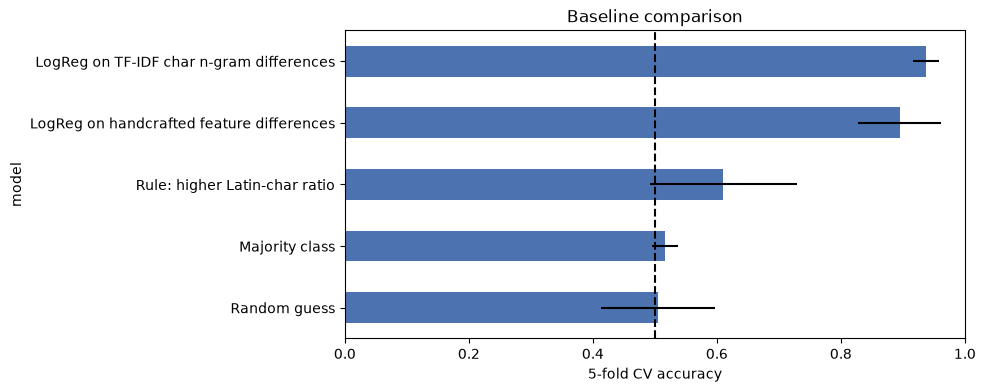

In [16]:
ax = results.plot.barh(x="model", y="cv_acc_mean", xerr="cv_acc_std", legend=False, color="#4C72B0")
ax.axvline(0.5, color="k", ls="--"); ax.set_xlim(0, 1); ax.set_xlabel("5-fold CV accuracy")
plt.title("Baseline comparison"); plt.gca().invert_yaxis(); plt.show()

### 4.1 Which hand-crafted features matter?

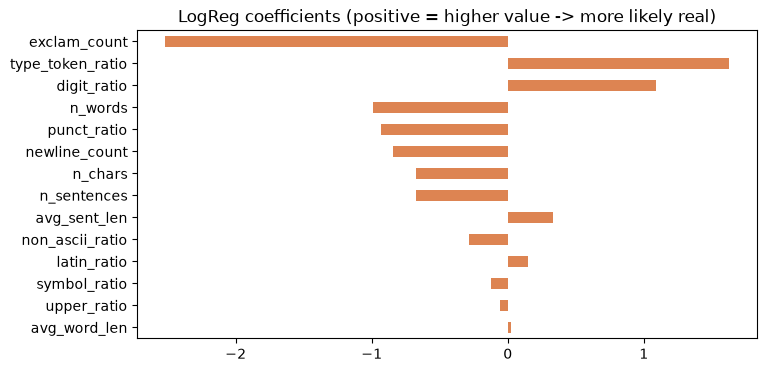

In [17]:
fe_model = FeatureDiffLR().fit(train)
fe_model.feature_importance().plot.barh(color="#DD8452")
plt.title("LogReg coefficients (positive = higher value -> more likely real)")
plt.gca().invert_yaxis(); plt.show()

### 4.2 Error analysis — pairs the best baseline gets wrong

In [18]:
best_key = max(cv_out, key=lambda k: cv_out[k]["mean"])
wrong = train[cv_out[best_key]["oof"] != train["real_text_id"].values]
print(f"best baseline: {ALL_BASELINES[best_key].name} | wrong on {len(wrong)} / {len(train)} pairs")
for _, row in wrong.head(2).iterrows():
    k = int(row.real_text_id)
    print(f"\n===== article {row.id} (real = file_{k}) =====")
    print("[REAL]", row[f"text_{k}"][:400])
    print("[FAKE]", row[f"text_{3-k}"][:400])

best baseline: LogReg on TF-IDF char n-gram differences | wrong on 6 / 95 pairs

===== article 65 (real = file_1) =====
[REAL] The SPHERE instrument is designed for high-quality imaging of many stars, and its operational plan, particularly a significant survey backed by its development team, will enable the direct detection of several giant planets in different environments. Completing this work on schedule will make an important contribution to the competitive field of extrasolar planet research, including their formatio
[FAKE] The SPHERE instrument is designed to capture very clear images of stars, and its operation plan, particularly a significant survey backed by its development group, will enable the direct detection of several giant planets in different environments. Completing this work on schedule will make an important contribution to the competitive field of extrasolar planet research, including their formation,

===== article 69 (real = file_2) =====
[REAL] The antennas will

## 5. Kaggle submission (best baseline)

In [19]:
best_model = ALL_BASELINES[best_key]().fit(train)
pred = best_model.predict(test)
sub = save_submission(test["id"], pred, "submission.csv")
print(sub["real_text_id"].value_counts())
sub.head()

real_text_id
1    564
2    504
Name: count, dtype: int64


,id,real_text_id
0,0,2
1,1,2
2,2,1
3,3,1
4,4,2


In [20]:
# Submit from Colab (max 3 submissions/day). Then record the public score in the README.
# !kaggle competitions submit -c {COMPETITION} -f submission.csv -m "A1 baseline: {ALL_BASELINES[best_key].name}"
# !kaggle competitions submissions -c {COMPETITION}

## 6. Summary & next steps
| Model | 5-fold CV accuracy | Kaggle public score |
|---|---|---|
| Random guess | 0.505 ± 0.092 | – |
| Majority class | 0.516 ± 0.021 | – |
| Latin-ratio rule | 0.611 ± 0.118 | – |
| Feature-diff LogReg | 0.895 ± 0.067 | – |
| TF-IDF-diff LogReg | **0.937 ± 0.021** | _fill in after submitting_ |

**Takeaways**
- The organizers' rule (Latin-letter ratio) only reaches ~61% because most pairs contain no foreign characters at all.
- A handful of interpretable statistics (length, exclamation marks, line breaks, digits) already reaches ~90%.
- Character n-gram TF-IDF is the strongest baseline (~94%). Its remaining errors are mostly pairs where the fake is a near-copy of the real text with a few words changed.

**Ideas for Assignment 2**
- Fine-tune a small transformer (e.g. DeBERTa / RoBERTa) as a pairwise (cross-encoder / Siamese) classifier.
- Use a reference language model's perplexity: fake texts should look less "natural".
- Compare the two texts directly (word-level diff, semantic similarity) to catch near-identical pairs.
- Combine rules, hand-crafted features and learned models in an ensemble.